# The 1644 Ming crisis: a generation of artists and scientists not trained
Does the crisis (rebellions from 1628, fall of Beijing in 1644, end of the Southern Ming in 1662) leave a hole in the cohorts born during it, which would explain a decline of cultural production one generation later? Only birth years, only culture and science, visual only.

**Territory**: individuals matched to the Ming, Later Jin, Li Zicheng (Shun), Southern Ming or Qing polity (`humans_clean_enriched_v3`), taken together. **Birth years and occupations**: `cultura_enriched_v3.2` (copy taken before the polity ingestion). **Culture / science**: one Wikidata occupation classified "Culture" or "Discovery/Science".

In [1]:
import tempfile

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import MaxNLocator
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2_before_polities.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'

TERRITORY_POLITIES = ['Ming Dynasty', 'Later Jin Dynasty', 'Li Zicheng', 'Southern Ming', 'Qing Dynasty']
DOMAINS = {'Culture': 'culture', 'Discovery/Science': 'science'}
BIRTH_START, BIRTH_END = 1550, 1750
BASELINE = (1600, 1630)
CRISIS_START, FALL_OF_BEIJING, CRISIS_END = 1628, 1644, 1662
TOP_NAMES = 12

DOMAIN_COLORS = {'culture': BLUE, 'science': GREEN}
CRISIS_BORN_COLOR = RED
CRISIS_SHADE = {'color': PALE_GREY, 'lw': 0, 'zorder': 0}

apply_style()

## External data
None. The crisis years (1628, 1644, 1662) are the only constants not read from the database.

## Load data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql('''
    CREATE TEMP TABLE territory_individuals AS
    SELECT DISTINCT entity.qid AS qid
    FROM   (SELECT entity, unnest(polity) AS polity_match FROM polity_db.individual_enriched)
    WHERE  list_contains($names, polity_match.polity.name)
''', params={'names': TERRITORY_POLITIES})

producers = con.sql('''
    WITH person_occupation AS (
        SELECT territory_individuals.qid, unnest(individual.occupation).entity.qid AS occupation_qid
        FROM   territory_individuals
        JOIN   individual ON individual.entity.qid = territory_individuals.qid
    )
    SELECT DISTINCT person_occupation.qid,
           occupation.meta_occupation,
           individual_enriched.entity.label_en        AS name,
           individual_enriched.entity.description     AS description,
           individual_enriched.birth_date.year        AS birth_year,
           individual_enriched.birth_date.source      AS birth_source,
           len(individual.sitelink)                   AS sitelinks
    FROM   person_occupation
    JOIN   occupation          ON occupation.entity.qid = person_occupation.occupation_qid
    JOIN   individual          ON individual.entity.qid = person_occupation.qid
    JOIN   individual_enriched ON individual_enriched.entity.qid = person_occupation.qid
    WHERE  list_contains($domains, occupation.meta_occupation)
''', params={'domains': list(DOMAINS)}).pl().with_columns(pl.col('meta_occupation').replace(DOMAINS).alias('domain'))
con.close()

print(f"culture or science individuals on the territory: {producers['qid'].n_unique():,}")
producers.sample(5, seed=42)

culture or science individuals on the territory: 3,642


qid,meta_occupation,name,description,birth_year,birth_source,sitelinks,domain
str,str,str,str,i64,str,i64,str
"""Q45614172""","""Culture""","""He Huisheng""","""Qing dynasty person CBDB = 788…",1800,"""wikidata""",0,"""culture"""
"""Q702918""","""Discovery/Science""","""Ma Huan""","""Ming dynasty translator, voyag…",1380,"""wikidata""",22,"""science"""
"""Q32019""","""Culture""","""Luo Ping""","""Chinese painter of the Qing Dy…",1733,"""wikidata""",13,"""culture"""
"""Q15938606""","""Culture""","""Ma Junshi""","""person, CBDB ID = 368816""",1876,"""wikidata""",1,"""culture"""
"""Q10920336""","""Culture""",null,null,1741,"""wikidata""",1,"""culture"""


## Preprocessing
### Births per decade
A cohort is **born during the crisis** when its whole decade of birth falls between 1628 and 1662: the 1630s, 1640s and 1650s.

In [3]:
born = producers.filter(pl.col('birth_year').is_between(BIRTH_START, BIRTH_END - 1)).with_columns(
    (pl.col('birth_year') // 10 * 10).alias('decade')
)
print(f"rows born {BIRTH_START}-{BIRTH_END - 1}: {born.height:,}, birth year estimated: {(born['birth_source'] == 'estimated').sum():,}")

decades = pl.DataFrame({'decade': range(BIRTH_START, BIRTH_END, 10)})
births = decades.join(
    born.group_by('decade', 'domain').len().pivot(on='domain', index='decade', values='len'), on='decade', how='left'
).fill_null(0).with_columns(
    ((pl.col('decade') >= CRISIS_START) & (pl.col('decade') + 10 <= CRISIS_END)).alias('born_during_crisis')
)
births

rows born 1550-1749: 1,378, birth year estimated: 71


decade,culture,science,born_during_crisis
i64,u32,u32,bool
1550,23,14,false
1560,27,13,false
1570,37,11,false
1580,52,13,false
1590,61,13,false
…,…,…,…
1700,42,11,false
1710,39,6,false
1720,50,11,false


### Pre-crisis level and missing births
Reference level = births per decade averaged over the cohorts born 1600-1629, the last generation trained under the Ming. For the cohorts born during the crisis, the gap below that level is drawn as the missing generation.

In [4]:
baseline = {domain: births.filter(pl.col('decade').is_between(BASELINE[0], BASELINE[1] - 1))[domain].mean() for domain in DOMAIN_COLORS}
missing = births.filter(pl.col('born_during_crisis')).select(
    'decade', *DOMAIN_COLORS, *[(baseline[domain] - pl.col(domain)).clip(lower_bound=0).alias(f'missing_{domain}') for domain in DOMAIN_COLORS]
)
print({domain: round(level, 1) for domain, level in baseline.items()})
missing

{'culture': 94.3, 'science': 17.7}


decade,culture,science,missing_culture,missing_science
i64,u32,u32,f64,f64
1630,68,13,26.333333,4.666667
1640,76,11,18.333333,6.666667
1650,39,8,55.333333,9.666667


## Figures
### Figure 1: Cultural producers and scientists born per decade
Red: cohorts born during the crisis. Dashed line: level of the cohorts born 1600-1629. Hatched: the missing generation, births below that level among the cohorts born during the crisis.

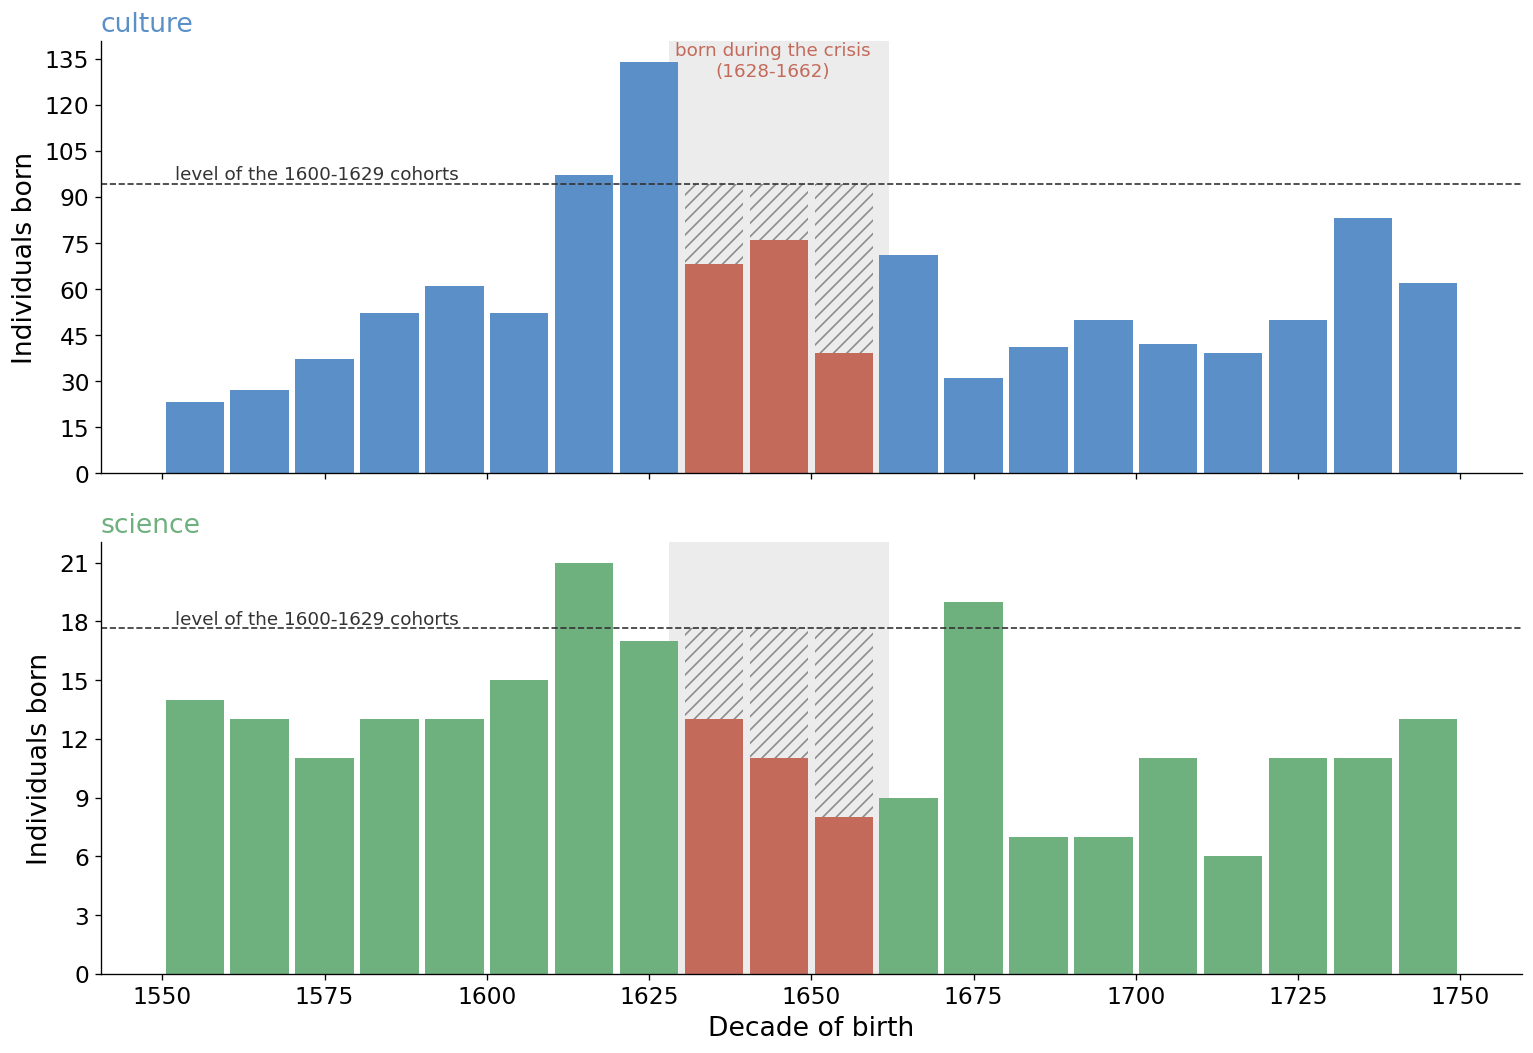

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, domain in zip(axes, DOMAIN_COLORS):
    colors = [CRISIS_BORN_COLOR if crisis else DOMAIN_COLORS[domain] for crisis in births['born_during_crisis']]
    ax.axvspan(CRISIS_START, CRISIS_END, **CRISIS_SHADE)
    ax.bar(births['decade'] + 5, births[domain], width=9, color=colors)
    ax.bar(missing['decade'] + 5, missing[f'missing_{domain}'], width=9, bottom=missing[domain], color='none', edgecolor=GREY, hatch='///', lw=0)
    ax.axhline(baseline[domain], color=TEXT, ls='--', lw=1)
    ax.text(BIRTH_START + 2, baseline[domain], 'level of the 1600-1629 cohorts', va='bottom', fontsize=SMALL_LEGEND_FONTSIZE, color=TEXT)
    ax.set_title(domain, color=DOMAIN_COLORS[domain], loc='left')
    ax.set_ylabel('Individuals born')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].text(FALL_OF_BEIJING, 1.0, 'born during the crisis\n(1628-1662)', transform=axes[0].get_xaxis_transform(),
             ha='center', va='top', fontsize=SMALL_LEGEND_FONTSIZE, color=CRISIS_BORN_COLOR)
axes[1].set_xlabel('Decade of birth')
plt.tight_layout()
plt.show()

## Who they are
### The last generation trained under the Ming (born 1600-1629) and the generation born during the crisis (1630-1659), most linked first

In [6]:
def top_names(start, end):
    return (
        born.filter(pl.col('birth_year').is_between(start, end - 1))
        .group_by('qid').agg(pl.col('name', 'description', 'birth_year', 'sitelinks').first(), pl.col('domain').unique().sort().str.join(' + '))
        .sort('sitelinks', descending=True)
        .select('name', 'birth_year', 'domain', 'description', 'sitelinks')
        .head(TOP_NAMES)
    )


top_names(1600, 1630)

name,birth_year,domain,description,sitelinks
str,i64,str,str,i64
"""Li Yu""",1611,"""culture + science""","""Chinese writer（1611—1680）""",41
"""Ferdinand Verbiest""",1623,"""science""","""Flemish Jesuit missionary in Q…",31
"""Martino Martini""",1614,"""culture + science""","""Italian Jesuit missionary, car…",28
"""Wang Fuzhi""",1619,"""culture + science""","""Chinese essayist, historian an…",27
"""Gu Yanwu""",1613,"""culture + science""","""Chinese philologist and geogra…",25
…,…,…,…,…
"""Jin Shengtan""",1610,"""culture + science""","""Chinese writer""",17
"""Huang Zongxi""",1610,"""science""","""Chinese naturalist, political …",17
"""Liu Rushi""",1618,"""culture""","""Chinese courtesan (1618-1664);…",15


In [7]:
top_names(1630, 1660)

name,birth_year,domain,description,sitelinks
str,i64,str,str,i64
"""Kangxi Emperor""",1654,"""culture""","""3rd Emperor of the Qing dynast…",64
"""Shunzhi Emperor""",1638,"""culture""","""Qing Dynasty emperor of China …",52
"""Shitao""",1642,"""culture + science""","""Chinese painter and poet (1642…",43
"""Pu Songling""",1640,"""culture + science""","""Chinese writer (1640–1715)""",39
"""Zanabazar""",1635,"""culture""","""Tibetan Buddhist spiritual lea…",19
…,…,…,…,…
"""Kong Shangren""",1648,"""culture""","""Chinese writer""",15
"""Wang Hui""",1632,"""culture""","""Chinese painter (1632-1717)""",15
"""Wu Li""",1632,"""culture""","""Chinese painter (1632-1718)""",14


In [8]:
for domain in DOMAIN_COLORS:
    crisis_born = births.filter(pl.col('born_during_crisis'))[domain].sum()
    expected = baseline[domain] * births['born_during_crisis'].sum()
    print(f"{domain}: born 1630-1659 = {crisis_born}, at the 1600-1629 level = {expected:.0f}, missing = {expected - crisis_born:.0f} ({1 - crisis_born / expected:.0%})")

culture: born 1630-1659 = 183, at the 1600-1629 level = 283, missing = 100 (35%)
science: born 1630-1659 = 32, at the 1600-1629 level = 53, missing = 21 (40%)


## What the data shows
**A generation is missing.** Cultural producers born per decade rise from the 1550s to a peak with the cohort born in the 1620s (134), the last children trained under the Ming. The cohorts born during the crisis (1630s, 1640s, 1650s) are about a third smaller than the 1600-1629 level: about 100 cultural producers and 20 scientists are missing.

**The hole does not close.** After the crisis, births stay below the 1600-1629 level for about seventy years. Culture only returns close to it with the cohort born in the 1730s, and science passes it only once, with the cohort born in the 1670s.

**This explains what we see later.** These people start producing about 30-40 years after birth. Production during and right after the crisis (1640-1670) is made by the large cohorts born 1600-1629, trained before the fall. The small cohorts born during the crisis are the ones that should take over from about 1670, so the decline of cultural production in the late 17th century follows from the training gap of the 1630s-1650s. It is a delayed consequence of the crisis.

**Caveats.** Science is small (6-21 births per decade), so its signal is weak; culture carries the result. Most individuals come from CBDB. 21 cultural producers have the round birth year 1620; even without them, the 1620s stay the peak. The Qing territory reaches beyond China proper (Mongolia, Tibet: e.g. Zanabazar), which slightly inflates the later cohorts and therefore makes the hole, if anything, smaller than it is.